# TP Final — Etapa 3: comparación de modelos con MLflow
Recupera las ejecuciones existentes, compara las ocho configuraciones de los tres algoritmos y exporta resultados. **No reentrena modelos.**

In [0]:
import os
import tempfile
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import mlflow

In [0]:
# La etapa 2 creó el experimento en /Users/<usuario>/...
usuario = spark.sql('SELECT current_user() AS usuario').first()['usuario']
EXPERIMENTO = f'/Users/{usuario}/TP_Final_Insuficiencia_Cardiaca'
exp = mlflow.get_experiment_by_name(EXPERIMENTO)
if exp is None:
    raise ValueError(f'No se encontró {EXPERIMENTO}. Revisá la ruta del experimento de la etapa 2.')
print('Experimento:', exp.name, '| ID:', exp.experiment_id)

Experimento: /Users/racheluja@gmail.com/TP_Final_Insuficiencia_Cardiaca | ID: 3073000958018720


In [0]:
runs = mlflow.search_runs(experiment_ids=[exp.experiment_id],
                         filter_string="attributes.status = 'FINISHED'",
                         order_by=['attributes.start_time DESC'], max_results=1000)
if runs.empty:
    raise ValueError('El experimento no tiene ejecuciones finalizadas.')
# Recuperar una sesión completa, evitando mezclar ejecuciones de distintos entrenamientos.
runs = runs[runs.get('tags.study', pd.Series(index=runs.index, dtype=str)) == 'heart_failure_extended_v1'].copy()
if runs.empty:
    raise ValueError('Ejecutá primero el nuevo notebook 02 completo.')
counts = runs.groupby('tags.session_id')['tags.mlflow.runName'].nunique()
complete = counts[counts == 8].index
runs = runs[runs['tags.session_id'].isin(complete)]
if runs.empty:
    raise ValueError('No hay una sesión completa de 8 runs. Terminá el notebook 02.')
session_id = runs.iloc[0]['tags.session_id']
runs = runs[runs['tags.session_id'] == session_id].drop_duplicates('tags.mlflow.runName')
print('Sesión completa:', session_id)
columnas = {
    'tags.mlflow.runName': 'modelo',
    'run_id': 'run_id',
    'metrics.cv_roc_auc_mean': 'cv_roc_auc_mean',
    'metrics.cv_roc_auc_std': 'cv_roc_auc_std',
    'metrics.test_roc_auc': 'test_roc_auc',
    'metrics.test_sensitivity': 'test_sensitivity',
    'metrics.test_specificity': 'test_specificity',
    'metrics.test_precision': 'test_precision',
    'metrics.test_f1': 'test_f1',
    'metrics.test_accuracy': 'test_accuracy',
    'metrics.test_average_precision': 'test_average_precision',
}
no_encontradas = [c for c in columnas if c not in runs.columns]
if no_encontradas:
    raise ValueError(f'Faltan métricas registradas: {no_encontradas}')
comparacion = runs[list(columnas)].rename(columns=columnas)
comparacion = comparacion.sort_values('cv_roc_auc_mean', ascending=False).reset_index(drop=True)
display(comparacion)

Sesión completa: 18d5a6f44f7547bd8b5681a185721f66


modelo,run_id,cv_roc_auc_mean,cv_roc_auc_std,test_roc_auc,test_sensitivity,test_specificity,test_precision,test_f1,test_accuracy,test_average_precision
LR_barrido_C_10.0,1a3585d808fb46ab987ef1dbc564c5df,0.8044444444444444,0.04806972842600283,0.7342747111681642,0.5263157894736842,0.7560975609756098,0.5,0.5128205128205128,0.6833333333333333,0.5913748957259026
Regresion_logistica,655356031cae477a8cd3db7477f4b147,0.804068023989899,0.04953993125322106,0.7342747111681642,0.5263157894736842,0.7804878048780488,0.5263157894736842,0.5263157894736842,0.7,0.5913748957259026
LR_barrido_C_0.1,ab415d7a5ec74fcb983203b1d2b342d2,0.800954861111111,0.05166237802723042,0.7496790757381258,0.5263157894736842,0.7804878048780488,0.5263157894736842,0.5263157894736842,0.7,0.6156367977424069
LR_barrido_C_0.01,a17e867df4004c75bbb59071b319753e,0.7901799242424243,0.05501123099554926,0.7625160462130937,0.5263157894736842,0.8048780487804879,0.5555555555555556,0.5405405405405406,0.7166666666666667,0.6370360079291293
Random_Forest,dc03905a88374ebd8aa5269f4cd9b6cb,0.778962279040404,0.046924211437415236,0.7907573812580231,0.5263157894736842,0.8292682926829268,0.5882352941176471,0.5555555555555556,0.7333333333333333,0.5868162743201591
RF_depth3,7898906b3ca14cd0bea3abcc48261fb9,0.7785700757575758,0.043417641107451506,0.7894736842105263,0.5789473684210527,0.8048780487804879,0.5789473684210527,0.5789473684210527,0.7333333333333333,0.6553638876819219
LightGBM,4d1e16249e58472880f9f3eb22231123,0.7542747790404041,0.029644618315668315,0.7702182284980744,0.47368421052631576,0.8292682926829268,0.5625,0.5142857142857142,0.7166666666666667,0.5648236358222914
LGBM_50_arboles,9cf3434ed83848ff9b91f5caac77156c,0.7475686553030303,0.040264374244186885,0.8010269576379974,0.42105263157894735,0.9024390243902439,0.6666666666666666,0.5161290322580645,0.75,0.5939817310258613


In [0]:
# Selección SOLO por validación cruzada. Test se informa, no se utiliza para elegir.
mejor = comparacion.iloc[0]
print('Modelo seleccionado por ROC-AUC media de CV:', mejor['modelo'])
print(f"ROC-AUC CV: {mejor['cv_roc_auc_mean']:.3f} ± {mejor['cv_roc_auc_std']:.3f}")
print(f"ROC-AUC test (evaluación descriptiva): {mejor['test_roc_auc']:.3f}")
print('Nota: el test no se usa para ajustar ni seleccionar modelos.')

Modelo seleccionado por ROC-AUC media de CV: LR_barrido_C_10.0
ROC-AUC CV: 0.804 ± 0.048
ROC-AUC test (evaluación descriptiva): 0.734
Nota: el test no se usa para ajustar ni seleccionar modelos.


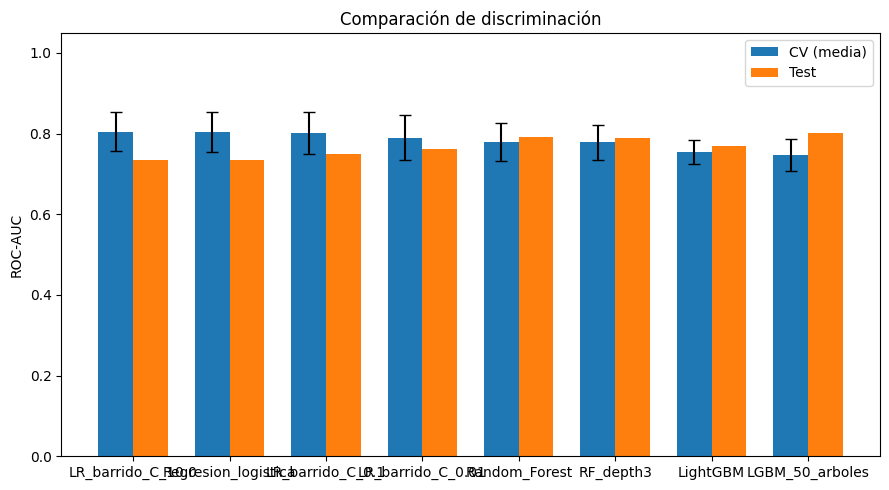

In [0]:
# Gráfico 1: CV ROC-AUC vs test ROC-AUC
x = np.arange(len(comparacion))
fig1, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - 0.18, comparacion['cv_roc_auc_mean'], width=0.36, label='CV (media)',
       yerr=comparacion['cv_roc_auc_std'], capsize=4)
ax.bar(x + 0.18, comparacion['test_roc_auc'], width=0.36, label='Test')
ax.set_xticks(x, comparacion['modelo'])
ax.set_ylabel('ROC-AUC')
ax.set_ylim(0, 1.05)
ax.set_title('Comparación de discriminación')
ax.legend()
fig1.tight_layout()
plt.show()

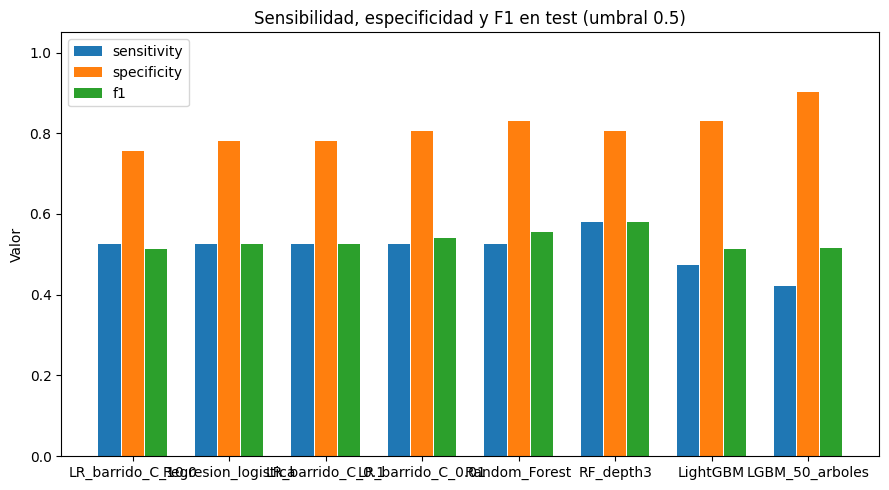

In [0]:
# Gráfico 2: métricas a umbral 0.5 en test
metricas = ['test_sensitivity', 'test_specificity', 'test_f1']
fig2, ax = plt.subplots(figsize=(9, 5))
for i, metrica in enumerate(metricas):
    ax.bar(x + (i - 1) * 0.24, comparacion[metrica], width=0.23,
           label=metrica.replace('test_', ''))
ax.set_xticks(x, comparacion['modelo'])
ax.set_ylabel('Valor')
ax.set_ylim(0, 1.05)
ax.set_title('Sensibilidad, especificidad y F1 en test (umbral 0.5)')
ax.legend()
fig2.tight_layout()
plt.show()

In [0]:
# Exportación local y copia al volumen Unity Catalog para GitHub.
# Se genera un informe con valores reales, sin inventar resultados.
BASE = '/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure'
with tempfile.TemporaryDirectory() as tmp:
    archivos = {
        'comparacion_modelos.csv': os.path.join(tmp, 'comparacion_modelos.csv'),
        'comparacion_auc.png': os.path.join(tmp, 'comparacion_auc.png'),
        'comparacion_metricas.png': os.path.join(tmp, 'comparacion_metricas.png'),
        'informe_resultados.md': os.path.join(tmp, 'informe_resultados.md'),
    }
    comparacion.to_csv(archivos['comparacion_modelos.csv'], index=False)
    fig1.savefig(archivos['comparacion_auc.png'], dpi=160, bbox_inches='tight')
    fig2.savefig(archivos['comparacion_metricas.png'], dpi=160, bbox_inches='tight')
    filas = '\n'.join(
        f"| {r.modelo} | {r.cv_roc_auc_mean:.3f} | {r.cv_roc_auc_std:.3f} | "
        f"{r.test_roc_auc:.3f} | {r.test_sensitivity:.3f} | {r.test_specificity:.3f} | {r.test_f1:.3f} |"
        for r in comparacion.itertuples(index=False)
    )
    informe = f'''# Resultados: predicción de mortalidad en insuficiencia cardíaca

## Comparación

| Modelo | CV ROC-AUC media | CV desviación estándar | Test ROC-AUC | Sensibilidad test | Especificidad test | F1 test |
|---|---:|---:|---:|---:|---:|---:|
{filas}

## Selección

Se selecciona **{mejor['modelo']}** por obtener el mayor ROC-AUC medio en la validación cruzada estratificada de cinco folds sobre entrenamiento. La evaluación en test se reporta una sola vez y no se utiliza para seleccionar modelos. Se compararon cinco configuraciones iniciales y un barrido de C de regresión logística (0.01, 0.1 y 10), usando los mismos folds. Se seleccionó por validación cruzada; el test se informa como evaluación descriptiva.

## Limitaciones

- Solo 299 pacientes: estimaciones inestables e intervalos de incertidumbre no calculados.
- Dataset observacional, sin validación externa ni evaluación de calibración.
- `time` se excluyó de los predictores para evitar información posterior al momento basal.
- `DEATH_EVENT` refleja fallecimiento durante seguimientos de distinta duración; no predice riesgo a un plazo fijo.
- El umbral 0.5 no fue optimizado clínicamente.
- La comparación no implica utilidad clínica ni autoriza decisiones asistenciales.

Fuente: UCI Heart Failure Clinical Records (dataset 519).
'''
    with open(archivos['informe_resultados.md'], 'w', encoding='utf-8') as f:
        f.write(informe)
    print(informe)
    try:
        dbutils.fs.mkdirs(f'{BASE}/resultados')
        for nombre, origen in archivos.items():
            __import__('shutil').copyfile(origen, f'{BASE}/resultados/{nombre}')
        print('Archivos guardados en:', f'{BASE}/resultados')
        display(dbutils.fs.ls(f'{BASE}/resultados'))
    except Exception as e:
        print('No se pudo copiar al volumen:', repr(e))
        print('Los resultados se visualizaron; revisá permisos o exportá las figuras desde el notebook.')
plt.close(fig1)
plt.close(fig2)

# Resultados: predicción de mortalidad en insuficiencia cardíaca

## Comparación

| Modelo | CV ROC-AUC media | CV desviación estándar | Test ROC-AUC | Sensibilidad test | Especificidad test | F1 test |
|---|---:|---:|---:|---:|---:|---:|
| LR_barrido_C_10.0 | 0.804 | 0.048 | 0.734 | 0.526 | 0.756 | 0.513 |
| Regresion_logistica | 0.804 | 0.050 | 0.734 | 0.526 | 0.780 | 0.526 |
| LR_barrido_C_0.1 | 0.801 | 0.052 | 0.750 | 0.526 | 0.780 | 0.526 |
| LR_barrido_C_0.01 | 0.790 | 0.055 | 0.763 | 0.526 | 0.805 | 0.541 |
| Random_Forest | 0.779 | 0.047 | 0.791 | 0.526 | 0.829 | 0.556 |
| RF_depth3 | 0.779 | 0.043 | 0.789 | 0.579 | 0.805 | 0.579 |
| LightGBM | 0.754 | 0.030 | 0.770 | 0.474 | 0.829 | 0.514 |
| LGBM_50_arboles | 0.748 | 0.040 | 0.801 | 0.421 | 0.902 | 0.516 |

## Selección

Se selecciona **LR_barrido_C_10.0** por obtener el mayor ROC-AUC medio en la validación cruzada estratificada de cinco folds sobre entrenamiento. La evaluación en test se reporta una sola vez y no se utiliza 

path,name,size,modificationTime
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/comparacion_auc.png,comparacion_auc.png,44503,1792852808000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/comparacion_metricas.png,comparacion_metricas.png,48418,1792852808000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/comparacion_modelos.csv,comparacion_modelos.csv,1846,1792852808000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/informe_resultados.md,informe_resultados.md,1848,1792852809000
dbfs:/Volumes/workspace/bigdata_drrach/landing/tp_final_heart_failure/resultados/predicciones_modelo_recargado.csv,predicciones_modelo_recargado.csv,6561,1792851964000
